
# AI Resume Screening & Job Matching System

**Author:** Muhammad Abdullah  
**Field:** Data Science, Artificial Intelligence & Machine Learning  
**Technologies:** Python, Pandas, NumPy, Scikit-learn, NLP, TF-IDF, Cosine Similarity, Matplotlib, Seaborn

## 1. Project Overview

The AI Resume Screening & Job Matching System is a Natural Language Processing (NLP) project designed to compare resumes with a given job description.

The system analyzes resume text, identifies relevant technical skills, calculates text similarity, and ranks sample resumes according to their relevance to the selected job description.

This project demonstrates how Python and machine learning techniques can support resume analysis and job matching.


## 2. Project Workflow

1. Import libraries.
2. Create a synthetic resume dataset.
3. Define a target job description.
4. Clean and preprocess text.
5. Extract relevant skills.
6. Calculate TF-IDF similarity.
7. Generate a resume ranking.
8. Evaluate ranking performance.
9. Visualize and export results.

### 2.1. Responsible AI Disclaimer

This project is an educational portfolio prototype. It must not be used to automatically select or reject job applicants.

Similarity scores indicate text overlap and listed skill coverage; they do not establish a person's ability, job performance, or suitability. The sample data and evaluation labels are synthetic.

A human reviewer must remain responsible for any real recruitment assessment.



## 3. Install and Import Required Libraries

This section installs the Python libraries required for text processing, similarity calculation, data analysis, and visualization.

Google Colab already provides many commonly used data science libraries, but installing the required packages helps make the notebook easier to reproduce.


In [1]:

%pip -q install pandas numpy scikit-learn matplotlib seaborn

print("Required libraries are ready.")


Note: you may need to restart the kernel to use updated packages.
Required libraries are ready.



## 4. Import Python Libraries

In this section, we import the libraries needed throughout the project.

- `Pandas` and `NumPy` support data manipulation and numerical operations.
- `Matplotlib` and `Seaborn` support visualization.
- `TfidfVectorizer` converts text into numerical TF-IDF features.
- `cosine_similarity` measures the similarity between the job description and resume text.


In [2]:

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

pd.set_option("display.max_colwidth", 120)

print("AI Resume Screening project started successfully!")
print("All libraries imported successfully.")


AI Resume Screening project started successfully!
All libraries imported successfully.



## 5. Create Sample Resume Dataset

We create a synthetic dataset containing resume text and demonstration relevance labels. No real applicant information is used.


In [3]:

# Create a synthetic resume dataset

resume_data = [
    {
        "candidate_id": "C001",
        "resume_text": "Data Science graduate skilled in Python, SQL, Pandas, NumPy, machine learning, statistics, and data visualization.",
        "relevant": 1
    },
    {
        "candidate_id": "C002",
        "resume_text": "Machine learning enthusiast with Python, TensorFlow, deep learning, feature engineering, and model evaluation projects.",
        "relevant": 1
    },
    {
        "candidate_id": "C003",
        "resume_text": "Data analyst experienced in SQL, Power BI, Tableau, Excel, data cleaning, and dashboard development.",
        "relevant": 1
    },
    {
        "candidate_id": "C004",
        "resume_text": "Software developer skilled in JavaScript, HTML, CSS, web development, and API integration.",
        "relevant": 0
    },
    {
        "candidate_id": "C005",
        "resume_text": "Marketing graduate with experience in social media, content writing, advertising, and campaign planning.",
        "relevant": 0
    },
    {
        "candidate_id": "C006",
        "resume_text": "NLP project developer experienced in Python, natural language processing, text classification, and data cleaning.",
        "relevant": 1
    },
    {
        "candidate_id": "C007",
        "resume_text": "Database intern with SQL, MySQL, database design, queries, and data validation skills.",
        "relevant": 0
    },
    {
        "candidate_id": "C008",
        "resume_text": "Computer vision developer using Python, TensorFlow, deep learning, image classification, and model evaluation.",
        "relevant": 1
    },
    {
        "candidate_id": "C009",
        "resume_text": "Administrative assistant experienced in scheduling, documentation, communication, and office coordination.",
        "relevant": 0
    },
    {
        "candidate_id": "C010",
        "resume_text": "Entry-level data scientist skilled in Python, SQL, Pandas, NumPy, statistics, and predictive modeling.",
        "relevant": 1
    }
]

resumes = pd.DataFrame(resume_data)

print("Dataset created successfully!")
print("Dataset shape:", resumes.shape)

display(resumes)


Dataset created successfully!
Dataset shape: (10, 3)


,candidate_id,resume_text,relevant
0,C001,"Data Science graduate skilled in Python, SQL, Pandas, NumPy, machine learning, statistics, and data visualization.",1
1,C002,"Machine learning enthusiast with Python, TensorFlow, deep learning, feature engineering, and model evaluation projects.",1
2,C003,"Data analyst experienced in SQL, Power BI, Tableau, Excel, data cleaning, and dashboard development.",1
3,C004,"Software developer skilled in JavaScript, HTML, CSS, web development, and API integration.",0
4,C005,"Marketing graduate with experience in social media, content writing, advertising, and campaign planning.",0
5,C006,"NLP project developer experienced in Python, natural language processing, text classification, and data cleaning.",1
6,C007,"Database intern with SQL, MySQL, database design, queries, and data validation skills.",0
7,C008,"Computer vision developer using Python, TensorFlow, deep learning, image classification, and model evaluation.",1
8,C009,"Administrative assistant experienced in scheduling, documentation, communication, and office coordination.",0
9,C010,"Entry-level data scientist skilled in Python, SQL, Pandas, NumPy, statistics, and predictive modeling.",1


In [4]:

# Inspect dataset structure and data quality

print("Dataset information:")
resumes.info()

print("\nMissing values:")
display(resumes.isnull().sum())

print("\nDuplicate rows:", resumes.duplicated().sum())

print("\nDemonstration label distribution:")
display(resumes["relevant"].value_counts().sort_index())


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   candidate_id  10 non-null     object
 1   resume_text   10 non-null     object
 2   relevant      10 non-null     int64 
dtypes: int64(1), object(2)
memory usage: 372.0+ bytes

Missing values:


candidate_id    0
resume_text     0
relevant        0
dtype: int64


Duplicate rows: 0

Demonstration label distribution:


relevant
0    4
1    6
Name: count, dtype: int64


## 6. Define the Target Job Description

The job description represents an entry-level Data Scientist role and will be used to compare the sample resumes.


In [5]:

job_description = """
We are looking for an entry-level Data Scientist with skills in Python,
SQL, Pandas, NumPy, statistics, data analysis, machine learning,
data visualization, feature engineering, and model evaluation.
Experience with Scikit-learn, TensorFlow, Power BI, and NLP is beneficial.
"""

required_skills = [
    "python",
    "sql",
    "pandas",
    "numpy",
    "statistics",
    "data analysis",
    "machine learning",
    "data visualization",
    "feature engineering",
    "model evaluation",
    "scikit-learn",
    "tensorflow",
    "power bi",
    "nlp"
]

print("Target job description:")
print(job_description)

print("\nRequired skills:", required_skills)
print("Total listed skills:", len(required_skills))


Target job description:

We are looking for an entry-level Data Scientist with skills in Python,
SQL, Pandas, NumPy, statistics, data analysis, machine learning,
data visualization, feature engineering, and model evaluation.
Experience with Scikit-learn, TensorFlow, Power BI, and NLP is beneficial.


Required skills: ['python', 'sql', 'pandas', 'numpy', 'statistics', 'data analysis', 'machine learning', 'data visualization', 'feature engineering', 'model evaluation', 'scikit-learn', 'tensorflow', 'power bi', 'nlp']
Total listed skills: 14



## 7. Text Preprocessing

Clean resume and job-description text by converting it to lowercase, removing unnecessary punctuation, and normalizing whitespace.


In [6]:

def clean_text(text):
    """Normalize text for resume matching."""
    text = str(text).lower()
    text = re.sub(r"[^a-z0-9+#.\s]", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()


resumes["clean_resume"] = resumes["resume_text"].apply(clean_text)
clean_job_description = clean_text(job_description)

print("Original resume:")
print(resumes.loc[0, "resume_text"])

print("\nCleaned resume:")
print(resumes.loc[0, "clean_resume"])


Original resume:
Data Science graduate skilled in Python, SQL, Pandas, NumPy, machine learning, statistics, and data visualization.

Cleaned resume:
data science graduate skilled in python sql pandas numpy machine learning statistics and data visualization.


In [7]:

def extract_skills(text, skill_list):
    """Identify listed skills using simple phrase matching."""
    text = clean_text(text)
    found_skills = []

    for skill in skill_list:
        pattern = (
            r"(?<![a-z0-9])"
            + re.escape(clean_text(skill))
            + r"(?![a-z0-9])"
        )

        if re.search(pattern, text):
            found_skills.append(skill)

    return found_skills


resumes["matched_skills"] = resumes["clean_resume"].apply(
    lambda text: extract_skills(text, required_skills)
)

resumes["matched_skill_count"] = resumes["matched_skills"].apply(len)

display(
    resumes[
        ["candidate_id", "matched_skills", "matched_skill_count"]
    ]
)


,candidate_id,matched_skills,matched_skill_count
0,C001,"[python, sql, pandas, numpy, statistics, machine learning, data visualization]",7
1,C002,"[python, machine learning, feature engineering, model evaluation, tensorflow]",5
2,C003,"[sql, power bi]",2
3,C004,[],0
4,C005,[],0
5,C006,"[python, nlp]",2
6,C007,[sql],1
7,C008,"[python, model evaluation, tensorflow]",3
8,C009,[],0
9,C010,"[python, sql, pandas, numpy, statistics]",5



## 8. TF-IDF Vectorization

TF-IDF converts text into numerical features. We fit the vectorizer on the job description and resume texts so their similarity can be calculated.


In [8]:

documents = [clean_job_description] + resumes["clean_resume"].tolist()

tfidf_vectorizer = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 2)
)

tfidf_matrix = tfidf_vectorizer.fit_transform(documents)

print("TF-IDF matrix shape:", tfidf_matrix.shape)
print("Number of text features:", len(tfidf_vectorizer.get_feature_names_out()))


TF-IDF matrix shape: (11, 186)
Number of text features: 186


In [9]:

job_vector = tfidf_matrix[0:1]
resume_vectors = tfidf_matrix[1:]

similarity_scores = cosine_similarity(
    job_vector,
    resume_vectors
).flatten()

resumes["tfidf_similarity"] = similarity_scores

display(
    resumes[
        ["candidate_id", "tfidf_similarity"]
    ].sort_values(
        by="tfidf_similarity",
        ascending=False
    )
)


,candidate_id,tfidf_similarity
9,C010,0.381813
0,C001,0.351359
1,C002,0.271419
2,C003,0.149086
7,C008,0.106160
6,C007,0.068601
5,C006,0.065982
4,C005,0.025562
3,C004,0.000000
8,C009,0.000000


In [10]:

# Calculate how many required skills appear in each resume

def calculate_skill_coverage(matched_skills, required_skills):
    required_set = set(required_skills)
    matched_set = set(matched_skills)

    if not required_set:
        return 0.0

    return len(required_set & matched_set) / len(required_set)


resumes["skill_coverage"] = resumes["matched_skills"].apply(
    lambda skills: calculate_skill_coverage(
        skills, required_skills
    )
)

resumes["skill_coverage_pct"] = (
    resumes["skill_coverage"] * 100
).round(2)

display(
    resumes[
        ["candidate_id", "matched_skill_count", "skill_coverage_pct"]
    ]
)


,candidate_id,matched_skill_count,skill_coverage_pct
0,C001,7,50.00
1,C002,5,35.71
2,C003,2,14.29
3,C004,0,0.00
4,C005,0,0.00
5,C006,2,14.29
6,C007,1,7.14
7,C008,3,21.43
8,C009,0,0.00
9,C010,5,35.71


In [11]:

TEXT_WEIGHT = 0.70
SKILL_WEIGHT = 0.30

resumes["combined_score"] = (
    TEXT_WEIGHT * resumes["tfidf_similarity"]
    + SKILL_WEIGHT * resumes["skill_coverage"]
)

resumes["combined_score_pct"] = (
    resumes["combined_score"] * 100
).round(2)

print("Combined scores calculated successfully!")

display(
    resumes[
        [
            "candidate_id",
            "tfidf_similarity",
            "skill_coverage_pct",
            "combined_score_pct"
        ]
    ].sort_values(
        by="combined_score_pct",
        ascending=False
    )
)


Combined scores calculated successfully!


,candidate_id,tfidf_similarity,skill_coverage_pct,combined_score_pct
0,C001,0.351359,50.00,39.60
9,C010,0.381813,35.71,37.44
1,C002,0.271419,35.71,29.71
2,C003,0.149086,14.29,14.72
7,C008,0.106160,21.43,13.86
5,C006,0.065982,14.29,8.90
6,C007,0.068601,7.14,6.94
4,C005,0.025562,0.00,1.79
3,C004,0.000000,0.00,0.00
8,C009,0.000000,0.00,0.00


In [12]:

# Rank resumes by the combined demonstration score

ranking = (
    resumes.sort_values(
        by="combined_score",
        ascending=False
    )
    .reset_index(drop=True)
    .copy()
)

ranking.insert(
    0,
    "rank",
    range(1, len(ranking) + 1)
)

display(
    ranking[
        [
            "rank",
            "candidate_id",
            "combined_score_pct",
            "matched_skills"
        ]
    ]
)


,rank,candidate_id,combined_score_pct,matched_skills
0,1,C001,39.60,"[python, sql, pandas, numpy, statistics, machine learning, data visualization]"
1,2,C010,37.44,"[python, sql, pandas, numpy, statistics]"
2,3,C002,29.71,"[python, machine learning, feature engineering, model evaluation, tensorflow]"
3,4,C003,14.72,"[sql, power bi]"
4,5,C008,13.86,"[python, model evaluation, tensorflow]"
5,6,C006,8.90,"[python, nlp]"
6,7,C007,6.94,[sql]
7,8,C005,1.79,[]
8,9,C004,0.00,[]
9,10,C009,0.00,[]


In [13]:

def precision_at_k(ranked_ids, relevant_ids, k):
    if k <= 0:
        raise ValueError("k must be greater than zero")

    top_k = ranked_ids[:k]

    if not top_k:
        return 0.0

    relevant_in_top_k = sum(
        candidate_id in relevant_ids
        for candidate_id in top_k
    )

    return relevant_in_top_k / len(top_k)


def recall_at_k(ranked_ids, relevant_ids, k):
    if k <= 0:
        raise ValueError("k must be greater than zero")

    if not relevant_ids:
        return 0.0

    relevant_in_top_k = sum(
        candidate_id in relevant_ids
        for candidate_id in ranked_ids[:k]
    )

    return relevant_in_top_k / len(relevant_ids)


ranked_ids = ranking["candidate_id"].tolist()

relevant_ids = set(
    resumes.loc[
        resumes["relevant"] == 1,
        "candidate_id"
    ]
)

evaluation_results = []

for k in [3, 5, 10]:
    evaluation_results.append({
        "K": k,
        "Precision@K": round(
            precision_at_k(ranked_ids, relevant_ids, k), 3
        ),
        "Recall@K": round(
            recall_at_k(ranked_ids, relevant_ids, k), 3
        )
    })

evaluation_df = pd.DataFrame(evaluation_results)

display(evaluation_df)


,K,Precision@K,Recall@K
0,3,1.0,0.500
1,5,1.0,0.833
2,10,0.6,1.000


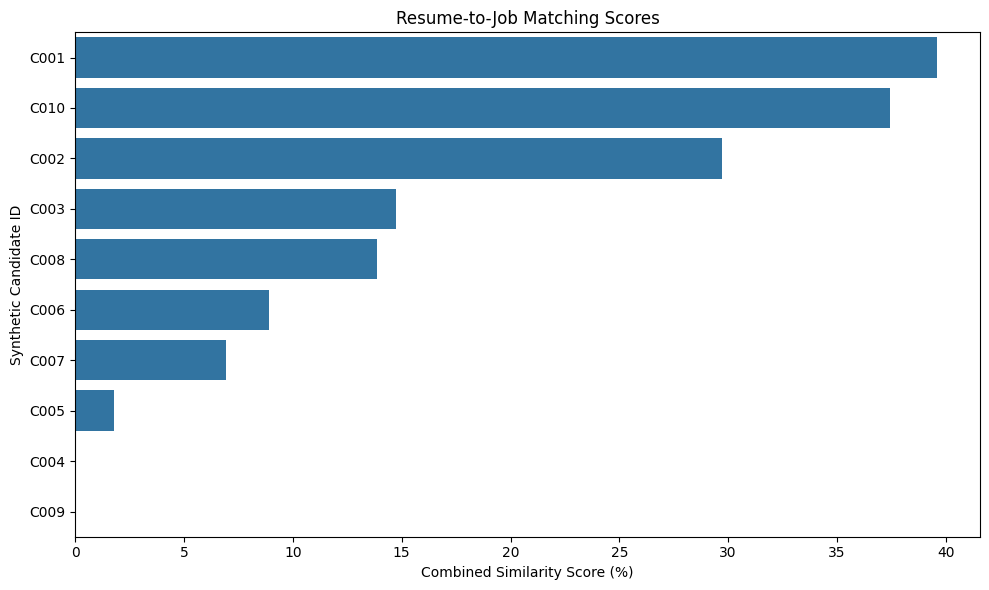

In [14]:

plt.figure(figsize=(10, 6))

sns.barplot(
    data=ranking,
    x="combined_score_pct",
    y="candidate_id"
)

plt.title("Resume-to-Job Matching Scores")
plt.xlabel("Combined Similarity Score (%)")
plt.ylabel("Synthetic Candidate ID")
plt.tight_layout()
plt.show()


In [15]:

from pathlib import Path

# Create output directory
output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

# Save ranked resumes
ranking.to_csv(
    output_dir / "resume_ranking.csv",
    index=False
)

# Save evaluation metrics
evaluation_df.to_csv(
    output_dir / "ranking_evaluation.csv",
    index=False
)

print("Files saved successfully!")
print("1. outputs/resume_ranking.csv")
print("2. outputs/ranking_evaluation.csv")


Files saved successfully!
1. outputs/resume_ranking.csv
2. outputs/ranking_evaluation.csv


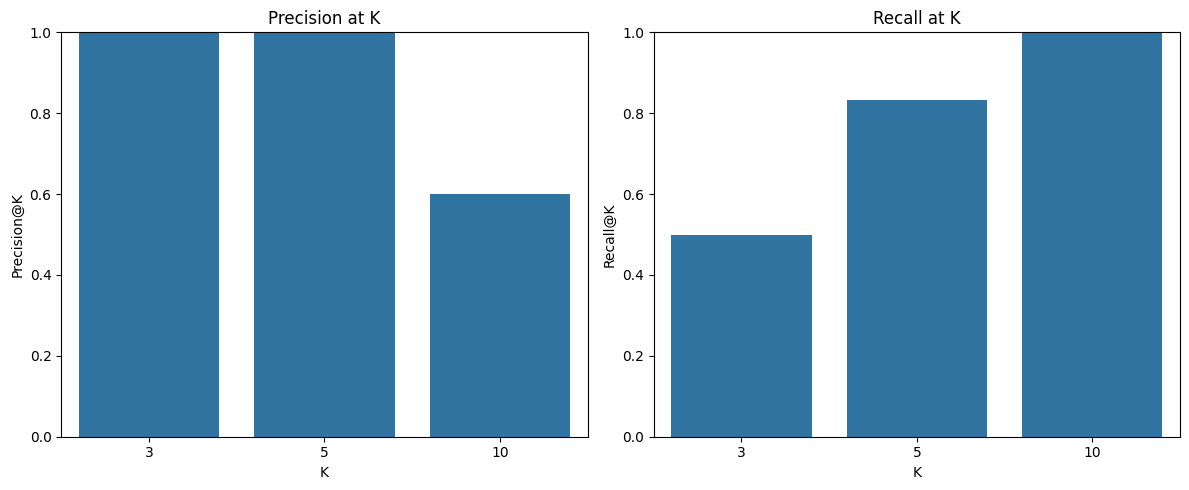

In [16]:

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.barplot(
    data=evaluation_df,
    x="K",
    y="Precision@K",
    ax=axes[0]
)
axes[0].set_title("Precision at K")
axes[0].set_ylim(0, 1)

sns.barplot(
    data=evaluation_df,
    x="K",
    y="Recall@K",
    ax=axes[1]
)
axes[1].set_title("Recall at K")
axes[1].set_ylim(0, 1)

plt.tight_layout()
plt.show()


In [17]:

from IPython.display import display, FileLink

display(FileLink("outputs/resume_ranking.csv"))
display(FileLink("outputs/ranking_evaluation.csv"))


e:\Projects\AI_Resume_Screening\outputs\resume_ranking.csv

e:\Projects\AI_Resume_Screening\outputs\ranking_evaluation.csv